# 02 — Especialização via Fine-Tuning LoRA (Qwen3-1.7B)

Objetivo da especialização (alinhado ao princípio *fine-tuning ensina como responder; RAG e ferramenta fornecem o conhecimento*):
- Ensinar disciplina de resposta estrita em JSON de 7 chaves sem texto excedente.
- Garantir citação exclusiva de `chunk_id`s presentes no contexto e leitura de `[DADOS_TECNICOS_ARBORGRID]`.
- Reforçar recusa fiel (`nao_consta`) quando o contexto for insuficiente ou fora de São Paulo, além de sanitização LGPD.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.common import DIR_ADAPTERS, DIR_ASSETS, DIR_DATA, load_jsonl

train_rows = load_jsonl(DIR_DATA / 'sft_train.jsonl')
val_rows = load_jsonl(DIR_DATA / 'sft_val.jsonl')
print(f'Treino SFT: {len(train_rows)} amostras | Validação SFT: {len(val_rows)} amostras')
display(pd.Series([r['familia'] for r in train_rows]).value_counts().rename('qtd_treino'))

Treino SFT: 360 amostras | Validação SFT: 60 amostras


normas_e_risco           62
emergencia_eletrica      62
nao_consta               61
agente_geosampa          59
lote_particular          32
emergencia_vida_clima    30
proibicao_via_publica    29
emergencia_clima_rede    14
emergencia_vida          11
Name: qtd_treino, dtype: int64

Configuração LoRA aplicada: {'r': 16, 'lora_alpha': 32, 'lora_dropout': 0.05, 'target_modules': ['up_proj', 'k_proj', 'down_proj', 'v_proj', 'gate_proj', 'o_proj', 'q_proj'], 'base_model_name_or_path': 'Qwen/Qwen3-1.7B'}


,epoch,step,eval_loss
0,1.0,23,0.133045
1,2.0,46,0.002065
2,3.0,69,0.000547


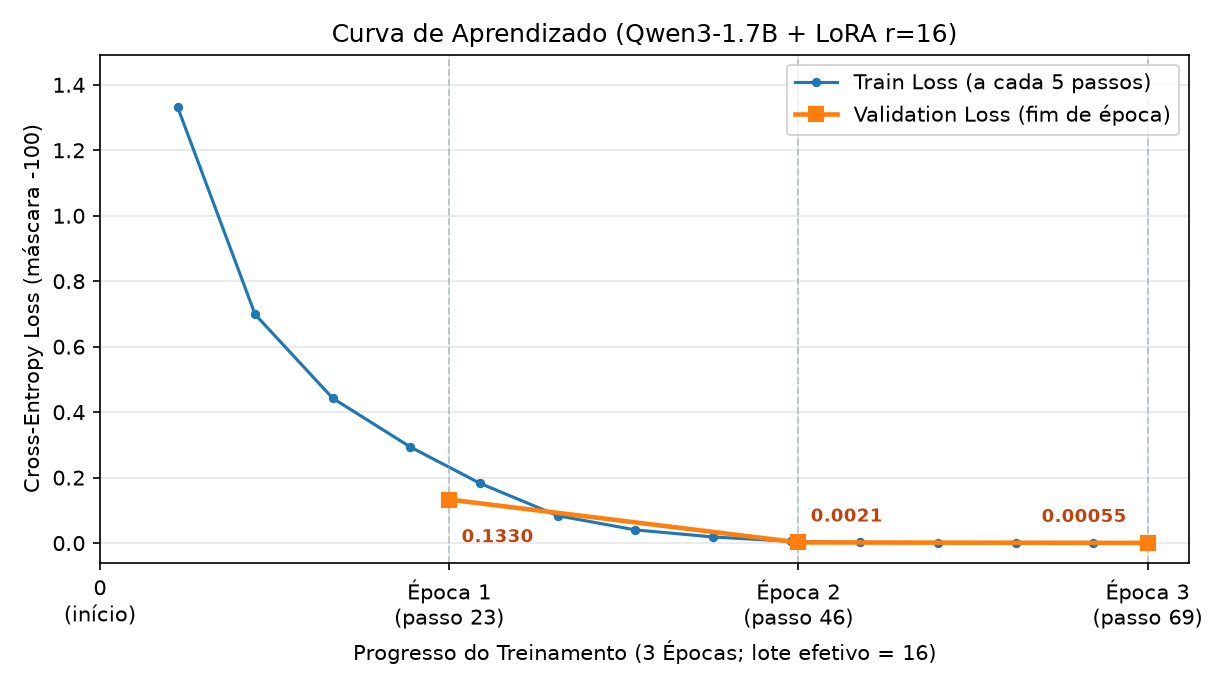

In [2]:
REEXECUTAR_TREINO = False  # True para retreinar o adaptador LoRA r=16 na GPU (~2 min)

if REEXECUTAR_TREINO or not (DIR_ADAPTERS / 'lora_arborgrid_r16' / 'adapter_config.json').exists():
    from scripts.train_lora import main as run_train
    run_train()

cfg = json.loads((DIR_ADAPTERS / 'lora_arborgrid_r16' / 'adapter_config.json').read_text(encoding='utf-8'))
print('Configuração LoRA aplicada:', {k: cfg[k] for k in ['r', 'lora_alpha', 'lora_dropout', 'target_modules', 'base_model_name_or_path']})
hist = json.loads((DIR_ASSETS / 'lora_train_history.json').read_text(encoding='utf-8'))
eval_losses = [h for h in hist if 'eval_loss' in h]
display(pd.DataFrame(eval_losses)[['epoch', 'step', 'eval_loss']])
display(Image(filename=str(DIR_ASSETS / 'curva_loss_lora.png')))

### Convergência Observada
Pela curva acima, com 3 épocas (`69` passos efetivos) e monitoramento por época (`eval_strategy='epoch'`), a perda de validação (`eval_loss`) cai continuamente (`0,1330 -> 0,0021 -> 0,00055`) sem sinal de *overfitting*, validando o adaptador `lora_arborgrid_r16`.